In [32]:
from pathlib import Path
import pandas as pd

images/ folder ready!


In [33]:
RAW_DIR = Path(".")

tx = pd.read_excel(RAW_DIR / "Transactions Data.xlsx")
card_types = pd.read_csv(RAW_DIR / "Card Type Table.csv")
tx_types = pd.read_csv(RAW_DIR / "Transaction Type Table.csv")
tx_statuses = pd.read_csv(RAW_DIR / "Transaction Status Table.csv")

print(f"Transactions loaded: {tx.shape[0]:,} rows x {tx.shape[1]} columns")
print("Lookup tables loaded: card_types, tx_types, tx_statuses")

Transactions loaded: 26,783 rows x 14 columns
Lookup tables loaded: card_types, tx_types, tx_statuses


In [34]:
summary = pd.DataFrame({
    "dtype": tx.dtypes,
    "null_count": tx.isnull().sum(),
    "null_pct": (tx.isnull().mean() * 100).round(2),})
display(summary)

display(tx.head(3))

print("\n Sample TRANS_NO_INFO")
print(tx["TRANS_NO_INFO"].head(3).tolist())

,dtype,null_count,null_pct
TRANS_ID,int64,0,0.00
TRANS_DIGEST,object,12629,47.15
CARD_TYPE,int64,0,0.00
TRANS_NO_INFO,object,0,0.00
AMOUNT,int64,0,0.00
TRANSACTION_TYPE,int64,0,0.00
TRANSACTION_STATUS,int64,0,0.00
AUTH_CODE,object,2106,7.86
RESULT_CODE,int64,0,0.00
DATE_START,datetime64[ns],0,0.00


,TRANS_ID,TRANS_DIGEST,CARD_TYPE,TRANS_NO_INFO,AMOUNT,TRANSACTION_TYPE,TRANSACTION_STATUS,AUTH_CODE,RESULT_CODE,DATE_START,DATE_END,BANK_BATCH,ORIG_TRANS_ID,TRANSACTION_SOURCE
0,811677427,8baed7bcb7965208ff4c8460f7c176c0,1,"{TRANS_NO:'1451282_5R4_XDLOYZEY8OAQN73A','BANK...",78000,1,1,867181,990017,2024-06-01 00:07:55,2024-06-01 00:07:56,0.0,0,13
1,811677480,NaN,1,"{TRANS_NO:'1451282_5R4_XDLOYZEY8OAQN73A','BANK...",78000,2,3,867181,990018,2024-06-01 00:07:57,2024-06-01 22:53:08,1686.0,811677427,13
2,811850256,19512da82040463ed5f189999596cf50,1,"{TRANS_NO:'1451283_1S8_9PPZ69S3VA52COP0','BANK...",168000,1,1,05541D,990017,2024-06-01 02:25:06,2024-06-01 02:25:18,0.0,0,12



 Sample TRANS_NO_INFO
["{TRANS_NO:'1451282_5R4_XDLOYZEY8OAQN73A','BANK':'Bank_Blue'}", "{TRANS_NO:'1451282_5R4_XDLOYZEY8OAQN73A','BANK':'Bank_Blue'}", "{TRANS_NO:'1451283_1S8_9PPZ69S3VA52COP0','BANK':'Bank_Red'}"]


In [35]:
tx["TRANS_NO"] = tx["TRANS_NO_INFO"].astype(str).str.extract(r"TRANS_NO:'([^']+)'")
tx["BANK_RAW"] = tx["TRANS_NO_INFO"].astype(str).str.extract(r"'BANK':'([^']+)'")

In [36]:
print("Missing TRANS_NO:", tx["TRANS_NO"].isna().sum())
print("Missing BANK_RAW:", tx["BANK_RAW"].isna().sum())

Missing TRANS_NO: 0
Missing BANK_RAW: 0


In [37]:
print(f"\nExpected unique banks: 5 | Found: {tx['BANK_RAW'].nunique()}")
print("\nRaw bank value counts (reveals typos):")
print(tx["BANK_RAW"].value_counts(dropna=False))


Expected unique banks: 5 | Found: 7

Raw bank value counts (reveals typos):
BANK_RAW
Bank_Red        5436
Bank_Blue       5382
Bank_Orange     5318
Bank_Yellow     5211
Bank_Green      5190
Bank_green       220
Bank_Yelllow      26
Name: count, dtype: int64


In [38]:
bank_map = {"Bank_Blue": "Bank Blue",
    "Bank_Green": "Bank Green",
    "Bank_green": "Bank Green",
    "Bank_Orange": "Bank Orange",
    "Bank_Red": "Bank Red",
    "Bank_Yellow": "Bank Yellow",
    "Bank_Yelllow": "Bank Yellow",}
tx["BANK"] = tx["BANK_RAW"].map(bank_map)

assert tx["BANK"].isna().sum() == 0, "Unmapped bank found!"
assert tx["BANK"].nunique() == 5, "Expected exactly 5 banks!"
assert tx.groupby("TRANS_NO")["BANK"].nunique().max() == 1, "A TRANS_NO has multiple banks!"

print("Clean bank value counts:")
print(tx["BANK"].value_counts())

Clean bank value counts:
BANK
Bank Red       5436
Bank Green     5410
Bank Blue      5382
Bank Orange    5318
Bank Yellow    5237
Name: count, dtype: int64


In [39]:
tx = (tx.merge(card_types, left_on="CARD_TYPE", right_on="TYPE_CODE", how="left")
      .rename(columns={"TYPE_DESC": "CARD_DESC"})
      .merge(tx_types, left_on="TRANSACTION_TYPE", right_on="TRANSACTION_CODE", how="left")
      .rename(columns={"TRANSACTION_DESC": "TX_TYPE_DESC"})
      .merge(tx_statuses, on="TRANSACTION_STATUS", how="left")
      .rename(columns={"TRANSACTION_DESC": "TX_STATUS_DESC"}))

assert tx["CARD_DESC"].isna().sum() == 0, "Unmapped CARD_TYPE!"
assert tx["TX_TYPE_DESC"].isna().sum() == 0, "Unmapped TRANSACTION_TYPE!"
assert tx["TX_STATUS_DESC"].isna().sum() == 0, "Unmapped TRANSACTION_STATUS!"

In [40]:
tx["DATE_START"] = pd.to_datetime(tx["DATE_START"])
tx["DATE_END"] = pd.to_datetime(tx["DATE_END"])
tx["AMOUNT_ZAR"] = tx["AMOUNT"] / 100.0
tx["DURATION_SEC"] = (tx["DATE_END"] - tx["DATE_START"]).dt.total_seconds()
tx["IS_SUCCESS"] = (tx["TX_TYPE_DESC"] == "Settlement") & (tx["TX_STATUS_DESC"] == "Paid")

print("Joins and derived columns complete! Shape:", tx.shape)

Joins and derived columns complete! Shape: (26783, 25)


In [41]:
print("Transaction Type x Status Crosstab")
display(pd.crosstab(tx["TX_TYPE_DESC"], tx["TX_STATUS_DESC"], margins=True))

print(f"\nTotal stage rows: {len(tx):,}")
print(f"Total unique TRANS_NO: {tx['TRANS_NO'].nunique():,}")

success_rows = tx[tx["IS_SUCCESS"]]
dup_success_tx = success_rows.groupby("TRANS_NO").size()
print(f"Successful (Settlement + Paid) rows: {len(success_rows):,} | Unique TRANS_NO: {success_rows['TRANS_NO'].nunique():,}")
print(f"TRANS_NOs with >1 Settlement+Paid row: {(dup_success_tx > 1).sum()}")

print("TRANS_NOs with >1 Card Type:", (tx.groupby("TRANS_NO")["CARD_DESC"].nunique() > 1).sum())
print("TRANS_NOs with >1 Amount:", (tx.groupby("TRANS_NO")["AMOUNT"].nunique() > 1).sum())

Transaction Type x Status Crosstab


TX_STATUS_DESC,Approved,Declined,Not Done,Paid,Refunded,Reversed,Stopped by Merchant,All
TX_TYPE_DESC,,,,,,,,
Authorise,12007,1708,392,0,0,0,0,14107
Refund,0,0,0,0,663,0,3,666
Settlement,0,0,0,12003,0,0,0,12003
System Reversal,0,0,0,0,0,1,6,7
All,12007,1708,392,12003,663,1,9,26783



Total stage rows: 26,783
Total unique TRANS_NO: 14,040
Successful (Settlement + Paid) rows: 12,003 | Unique TRANS_NO: 11,967
TRANS_NOs with >1 Settlement+Paid row: 23
TRANS_NOs with >1 Card Type: 10
TRANS_NOs with >1 Amount: 137


Question 1:
The client has asked the data team for the count total unique transactions, from the 15th of June up to and including the 15th of July, they also requested that the team provide the distribution of transactions by Card Type

Total unique transactions (15 Jun – 15 Jul 2024): 5,729
Successful unique transactions in window:       4,884


,Card Type,Unique_Transactions,Share_%
0,VISA,3769,65.79
1,MASTER CARD,1589,27.74
2,AMERICAN EXPRESS,274,4.78
3,DINERS CLUB,97,1.69


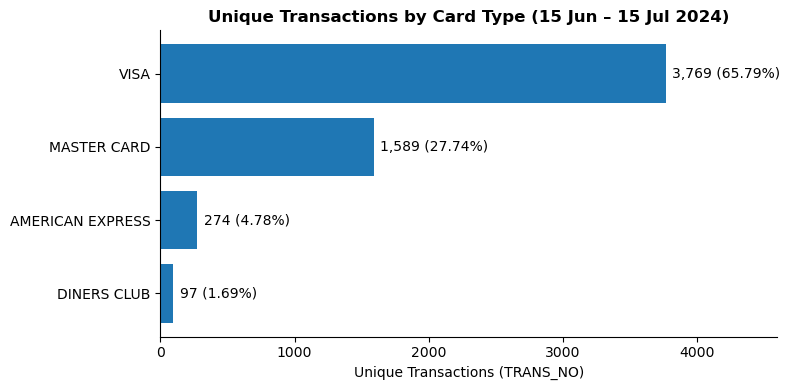

In [42]:
import matplotlib.pyplot as plt

q1_mask = (tx["DATE_START"] >= "2024-06-15 00:00:00") & (tx["DATE_START"] <= "2024-07-15 23:59:59")
q1_df = tx.loc[q1_mask].sort_values(["TRANS_NO", "DATE_START", "TRANS_ID"])

q1_unique = q1_df.groupby("TRANS_NO", as_index=False).first()
q1_total = len(q1_unique)
q1_success = q1_df.loc[q1_df["IS_SUCCESS"], "TRANS_NO"].nunique()

q1_card = (q1_unique["CARD_DESC"]
    .value_counts()
    .rename_axis("Card Type")
    .reset_index(name="Unique_Transactions"))
q1_card["Share_%"] = (q1_card["Unique_Transactions"] / q1_total * 100).round(2)

print(f"Total unique transactions (15 Jun – 15 Jul 2024): {q1_total:,}")
print(f"Successful unique transactions in window:       {q1_success:,}")
display(q1_card)

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = q1_card.sort_values("Unique_Transactions", ascending=True)
bars = ax.barh(plot_df["Card Type"], plot_df["Unique_Transactions"], color="#1f77b4")

for bar, pct in zip(bars, plot_df["Share_%"]):
    w = bar.get_width()
    ax.text(w + 50, bar.get_y() + bar.get_height() / 2, f"{int(w):,} ({pct}%)", va="center", fontsize=10)

ax.set_xlim(0, plot_df["Unique_Transactions"].max() * 1.22)
ax.set_title("Unique Transactions by Card Type (15 Jun – 15 Jul 2024)", fontsize=12, fontweight="bold")
ax.set_xlabel("Unique Transactions (TRANS_NO)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/q1_card_types.png", dpi=300, bbox_inches="tight")
plt.show()

Question 2:
The client wants to investigate their customer base to help inform their strategy, they have requested the data team to provide the total count of unique transactions and the transaction amounts by Bank for the total period of the transactional data provided

,All_Unique_transactions,All_Amount_ZAR,Success_Unique_transactions,Success_Amount_ZAR,Success_Rate_%
Bank Red,"2,859","R3,084,500.00","2,429","R2,562,457.00",84.96%
Bank Green,"2,844","R2,907,974.00","2,412","R2,422,603.00",84.81%
Bank Blue,"2,806","R3,098,306.00","2,398","R2,474,698.00",85.46%
Bank Orange,"2,792","R3,047,496.00","2,376","R2,615,040.00",85.10%
Bank Yellow,"2,739","R3,438,118.00","2,352","R2,398,917.00",85.87%
Total,"14,040","R15,576,394.00","11,967","R12,473,715.00",85.24%


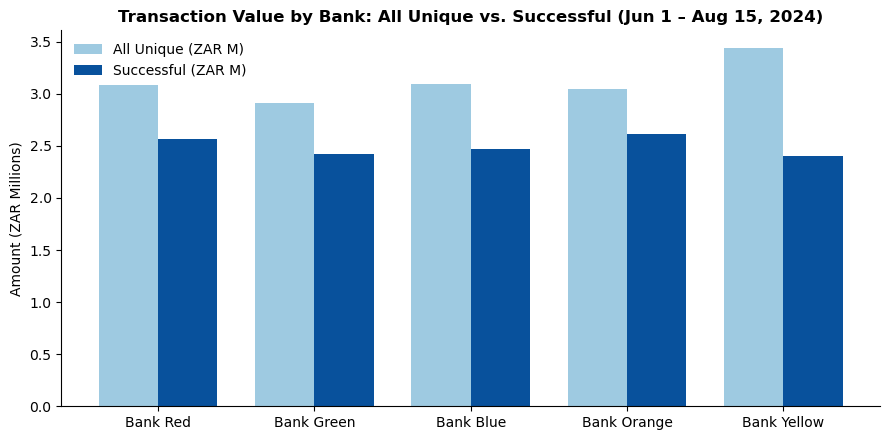

In [43]:
tx_sorted = tx.sort_values(["TRANS_NO", "DATE_START", "TRANS_ID"])
all_unique = tx_sorted.groupby("TRANS_NO", as_index=False).first()
success_unique = tx_sorted[tx_sorted["IS_SUCCESS"]].groupby("TRANS_NO", as_index=False).first()

q2_all = all_unique.groupby("BANK").agg(
    All_Unique_transactions=("TRANS_NO", "count"),
    All_Amount_ZAR=("AMOUNT_ZAR", "sum"),)
q2_success = success_unique.groupby("BANK").agg(
    Success_Unique_transactions=("TRANS_NO", "count"),
    Success_Amount_ZAR=("AMOUNT_ZAR", "sum"),)

q2_summary = q2_all.join(q2_success).sort_values("All_Unique_transactions", ascending=False)
q2_summary["Success_Rate_%"] = (q2_summary["Success_Unique_transactions"] / q2_summary["All_Unique_transactions"] * 100).round(2)

totals = pd.DataFrame(q2_summary[["All_Unique_transactions", "All_Amount_ZAR", "Success_Unique_transactions", "Success_Amount_ZAR"]].sum()).T
totals.index = ["Total"]
totals["Success_Rate_%"] = round(totals["Success_Unique_transactions"] / totals["All_Unique_transactions"] * 100, 2)

display(pd.concat([q2_summary, totals]).style.format({
    "All_Unique_transactions": "{:,.0f}",
    "All_Amount_ZAR": "R{:,.2f}",
    "Success_Unique_transactions": "{:,.0f}",
    "Success_Amount_ZAR": "R{:,.2f}",
    "Success_Rate_%": "{:.2f}%",}))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(q2_summary))
w = 0.38
ax.bar([i - w/2 for i in x], q2_summary["All_Amount_ZAR"] / 1e6, width=w, label="All Unique (ZAR M)", color="#9ecae1")
ax.bar([i + w/2 for i in x], q2_summary["Success_Amount_ZAR"] / 1e6, width=w, label="Successful (ZAR M)", color="#08519c")

ax.set_xticks(list(x))
ax.set_xticklabels(q2_summary.index)
ax.set_ylabel("Amount (ZAR Millions)")
ax.set_title("Transaction Value by Bank: All Unique vs. Successful (Jun 1 – Aug 15, 2024)", fontsize=12, fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/q2_bank_amounts.png", dpi=300, bbox_inches="tight")
plt.show()

Question 3:
Bank Green has requested a view of the total VISA card transactions for this client in the month of July and the ZAR amount of these transactions

In [44]:
july_green_visa = tx[(tx["BANK"] == "Bank Green")
    & (tx["CARD_DESC"] == "VISA")
    & (tx["DATE_START"].dt.month == 7)]

all_transactions = july_green_visa.drop_duplicates(subset="TRANS_NO")
print("Total VISA transactions:", len(all_transactions))
print("Total ZAR amount: R", round(all_transactions["AMOUNT_ZAR"].sum(), 2))

successful_transactions = july_green_visa[july_green_visa["IS_SUCCESS"]].drop_duplicates(subset="TRANS_NO")
print("\nSuccessful VISA transactions:", len(successful_transactions))
print("Successful ZAR amount: R", round(successful_transactions["AMOUNT_ZAR"].sum(), 2))

Total VISA transactions: 770
Total ZAR amount: R 762893.0

Successful VISA transactions: 623
Successful ZAR amount: R 608003.0


Question 4:
Bank Blue has requested the average time of a successful transaction during the day of the 25th of July 2024

In [45]:
q4 = tx[(tx["BANK"] == "Bank Blue")
    & (tx["IS_SUCCESS"] == True)
    & (tx["DATE_START"].dt.date == pd.to_datetime("2024-07-25").date())]
avg_sec = q4["DURATION_SEC"].mean()

print("Successful transactions:", len(q4))
print("Average time (seconds):", round(avg_sec, 1))
print("Average time (HH:MM:SS):", pd.to_timedelta(round(avg_sec), unit="s"))

Successful transactions: 31
Average time (seconds): 30941.0
Average time (HH:MM:SS): 0 days 08:35:41


Question 5:
The data provided includes transactions from the 1st June 2024 to the 15th of August 2024. The client wants a daily forecast the count of transactions up to the end of August 2024, specifically the total transaction count and successful transaction counts

In [46]:
tx["DATE"] = tx["DATE_START"].dt.floor("D")

daily = pd.DataFrame({"Total_transactions": tx.groupby("DATE")["TRANS_NO"].nunique(),
    "Successful_transactions": tx[tx["IS_SUCCESS"]].groupby("DATE")["TRANS_NO"].nunique(),}).asfreq("D", fill_value=0)

daily["Day"] = daily.index.day_name()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_avg = daily.groupby("Day")[["Total_transactions", "Successful_transactions"]].mean().reindex(day_order).round(1)

print("Average Daily Transactions by Day of Week:")
display(dow_avg)

Average Daily Transactions by Day of Week:


,Total_transactions,Successful_transactions
Day,,
Monday,251.4,200.3
Tuesday,225.5,186.4
Wednesday,232.3,193.1
Thursday,222.4,180.3
Friday,208.2,171.5
Saturday,93.8,80.4
Sunday,112.6,94.2


16-Day Forecast Sum -> Total: 2,994 | Successful: 2,462


,Date,Day,Forecast_Total,Forecast_Successful
0,2024-08-16,Friday,208,172
1,2024-08-17,Saturday,94,80
2,2024-08-18,Sunday,113,94
3,2024-08-19,Monday,251,200
4,2024-08-20,Tuesday,226,186
5,2024-08-21,Wednesday,232,193
6,2024-08-22,Thursday,222,180
7,2024-08-23,Friday,208,172
8,2024-08-24,Saturday,94,80
9,2024-08-25,Sunday,113,94


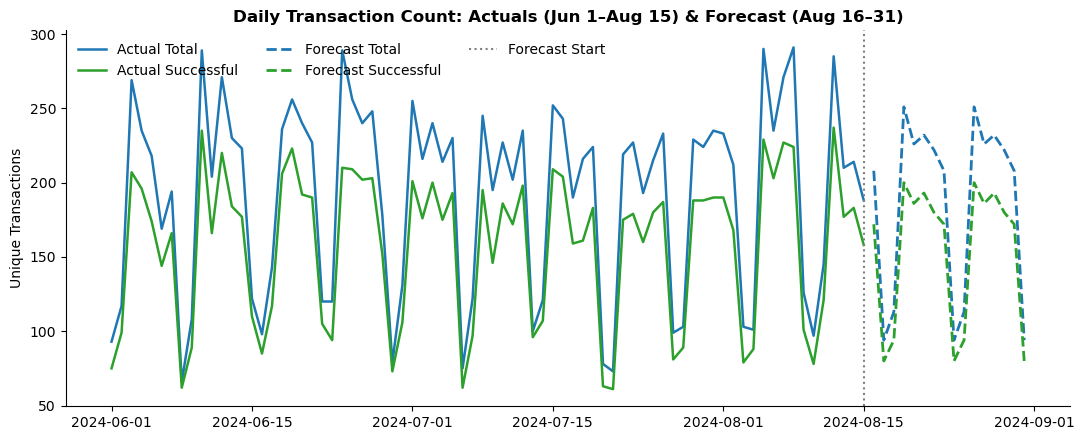

In [47]:
future_dates = pd.date_range("2024-08-16", "2024-08-31", freq="D")
forecast = pd.DataFrame({"Date": future_dates})
forecast["Day"] = forecast["Date"].dt.day_name()

forecast["Forecast_Total"] = forecast["Day"].map(dow_avg["Total_transactions"]).round().astype(int)
forecast["Forecast_Successful"] = forecast["Day"].map(dow_avg["Successful_transactions"]).round().astype(int)

print(f"16-Day Forecast Sum -> Total: {forecast['Forecast_Total'].sum():,} | Successful: {forecast['Forecast_Successful'].sum():,}")
display(forecast)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily["Total_transactions"], label="Actual Total", color="#1f77b4", linewidth=1.8)
ax.plot(daily.index, daily["Successful_transactions"], label="Actual Successful", color="#2ca02c", linewidth=1.8)

ax.plot(forecast["Date"], forecast["Forecast_Total"], "--", label="Forecast Total", color="#1f77b4", linewidth=2)
ax.plot(forecast["Date"], forecast["Forecast_Successful"], "--", label="Forecast Successful", color="#2ca02c", linewidth=2)

ax.axvline(pd.to_datetime("2024-08-15"), color="gray", linestyle=":", label="Forecast Start")
ax.set_title("Daily Transaction Count: Actuals (Jun 1–Aug 15) & Forecast (Aug 16–31)", fontsize=12, fontweight="bold")
ax.set_ylabel("Unique Transactions")
ax.legend(frameon=False, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/q5_daily_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

,Total_Transactions,Successful,Declined,Refunded,Success_Rate_%,Decline_Rate_%,Refund_Rate_%
CARD_DESC,,,,,,,
VISA,9179,7813.0,1092,408.0,85.12,11.90,5.22
MASTER CARD,3934,3259.0,566,152.0,82.84,14.39,4.66
AMERICAN EXPRESS,723,713.0,11,18.0,98.62,1.52,2.52
DINERS CLUB,213,183.0,24,16.0,85.92,11.27,8.74
OTHER,1,0.0,1,0.0,0.00,100.00,NaN


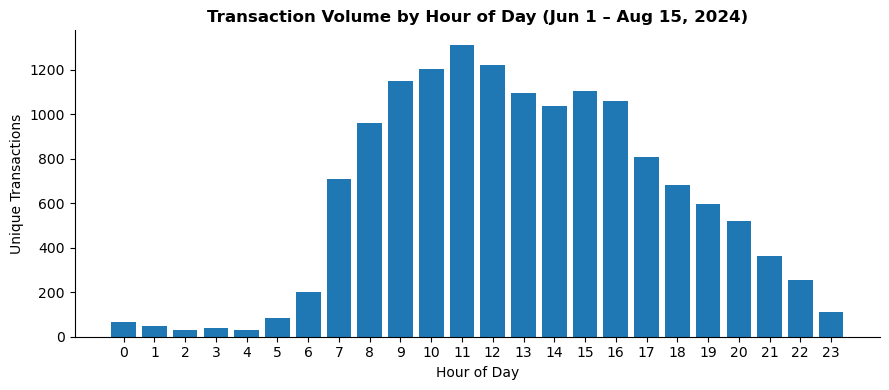

In [48]:
card_kpis = pd.DataFrame({"Total_Transactions": tx.groupby("CARD_DESC")["TRANS_NO"].nunique(),
    "Successful": tx[tx["IS_SUCCESS"]].groupby("CARD_DESC")["TRANS_NO"].nunique(),
    "Declined": tx[tx["TX_STATUS_DESC"] == "Declined"].groupby("CARD_DESC")["TRANS_NO"].nunique(),
    "Refunded": tx[tx["TX_STATUS_DESC"] == "Refunded"].groupby("CARD_DESC")["TRANS_NO"].nunique(),}).fillna(0)

card_kpis["Success_Rate_%"] = (card_kpis["Successful"] / card_kpis["Total_Transactions"] * 100).round(2)
card_kpis["Decline_Rate_%"] = (card_kpis["Declined"] / card_kpis["Total_Transactions"] * 100).round(2)
card_kpis["Refund_Rate_%"] = (card_kpis["Refunded"] / card_kpis["Successful"] * 100).round(2)

display(card_kpis.sort_values("Total_Transactions", ascending=False))

hourly = tx.groupby(tx["DATE_START"].dt.hour)["TRANS_NO"].nunique()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(hourly.index, hourly.values, color="#1f77b4")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Unique Transactions")
ax.set_title("Transaction Volume by Hour of Day (Jun 1 – Aug 15, 2024)", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/q7_hourly_volume.png", dpi=300, bbox_inches="tight")
plt.show()

Question 6:
Given the data provided, describe a data dashboard that would help this client in future and include any other elements that you feel would be valuable in the data visualisation

1. KPI Summary Cards: Total Unique Transactions, Successful Transactions, Settled Value (ZAR), Success Rate (%), Decline Rate (%), and Refund Rate (%).
2. Daily Volume & Forecast Trend: Line chart of daily Total vs. Successful transactions with a 7-day moving average and rest-of-month forecast.
3. Conversion Funnel & Failure Breakdown: stage funnel (`Authorise` -> `Approved` -> `Settlement` -> `Paid`) plus Declined/Not Done breakdown by `RESULT_CODE`, `BANK`, and `CARD_TYPE`
4. Bank & Card Performance Matrix: side-by-side comparison of volume, ZAR value, success rate, and refund rate across the 5 banks and card schemes.
5. Authorisation speed vs. batch settlement lag, `BANK_BATCH` reconciliation, and alerts for unclosed rows (`DATE_END` nulls) or duplicate settlements.
6. Interactive Filters: Date range, Bank, Card Type, `TRANSACTION_SOURCE`, and Transaction Status.

Question 7:
From what you have learned about this client’s transactional data what insights would you be able to share with the business and/or the client

- weekday volume (208–251/day) is more than 2x weekend volume (94–113/day), peaking on Mondays and between 09:00–12:00, system maintenance should be scheduled between 00:00–05:00 when traffic is lowest
- american Express has the highest success rate (98.62%, 1.52% decline), while MasterCard has the lowest (82.84%, 14.39% decline), diners club shows the highest refund rate (8.74%)
- uniform Bank Performance, all the 5 banks convert at 84.8%–85.9%, showing no single bank outage, though Bank Blue has the highest refund rate of 5.96%
- standardizing `Bank_green` and `Bank_Yelllow` typos, investigating the 23 transactions with duplicate `Settlement + Paid` rows, and reviewing the 392 `Not Done` authorisations will improve reporting accuracy and revenue recovery

In [53]:
# Question 1
q1_sql = """
SELECT
    c.TYPE_DESC AS Card_Type,
    COUNT(DISTINCT t.TRANS_NO) AS Unique_Transactions
FROM transactions t
JOIN card_type c ON t.CARD_TYPE = c.TYPE_CODE
WHERE t.DATE_START BETWEEN '2024-06-15 00:00:00' AND '2024-07-15 23:59:59'
GROUP BY c.TYPE_DESC
ORDER BY Unique_Transactions DESC;
"""

# Question 2
q2_sql = """
SELECT
    BANK,
    COUNT(*) AS Unique_Transactions,
    ROUND(SUM(AMOUNT_ZAR), 2) AS Total_Amount_ZAR
FROM (
    SELECT TRANS_NO, BANK, AMOUNT_ZAR,
           ROW_NUMBER() OVER (PARTITION BY TRANS_NO ORDER BY DATE_START, TRANS_ID) AS rn
    FROM transactions
) sub
WHERE rn = 1
GROUP BY BANK
ORDER BY Unique_Transactions DESC;
"""

# Question 3
q3_sql = """
SELECT
    COUNT(*) AS Total_VISA_Transactions,
    ROUND(SUM(AMOUNT_ZAR), 2) AS Total_ZAR
FROM (
    SELECT t.TRANS_NO, t.AMOUNT_ZAR,
           ROW_NUMBER() OVER (PARTITION BY t.TRANS_NO ORDER BY t.DATE_START, t.TRANS_ID) AS rn
    FROM transactions t
    JOIN card_type c ON t.CARD_TYPE = c.TYPE_CODE
    WHERE t.BANK = 'Bank Green'
      AND c.TYPE_DESC = 'VISA'
      AND t.DATE_START >= '2024-07-01'
      AND t.DATE_START < '2024-08-01') sub
WHERE rn = 1;
"""

# Question 4
q4_sql = """
SELECT
    COUNT(*) AS Successful_Transactions,
    ROUND(AVG(t.DURATION_SEC), 1) AS Avg_Seconds,
    ROUND(AVG(t.DURATION_SEC) / 60.0, 2) AS Avg_Minutes
FROM transactions t
JOIN transaction_type tt ON t.TRANSACTION_TYPE = tt.TRANSACTION_CODE
JOIN transaction_status ts ON t.TRANSACTION_STATUS = ts.TRANSACTION_STATUS
WHERE t.BANK = 'Bank Blue'
  AND tt.TRANSACTION_DESC = 'Settlement'
  AND ts.TRANSACTION_DESC = 'Paid'
  AND DATE(t.DATE_START) = '2024-07-25';
"""

for title, query in [("Q1", q1_sql), ("Q2", q2_sql), ("Q3", q3_sql), ("Q4", q4_sql)]:
    print(f"=== {title} ===")
    display(pd.read_sql_query(query, conn))

=== Q1 ===


,Card_Type,Unique_Transactions
0,VISA,3770
1,MASTER CARD,1590
2,AMERICAN EXPRESS,274
3,DINERS CLUB,97


=== Q2 ===


,BANK,Unique_Transactions,Total_Amount_ZAR
0,Bank Red,2859,3084500.0
1,Bank Green,2844,2907974.0
2,Bank Blue,2806,3098306.0
3,Bank Orange,2792,3047496.0
4,Bank Yellow,2739,3438118.0


=== Q3 ===


,Total_VISA_Transactions,Total_ZAR
0,770,762893.0


=== Q4 ===


,Successful_Transactions,Avg_Seconds,Avg_Minutes
0,31,30941.0,515.68
